# Coursework archive

This notebook retains the original model code and saved outputs. Read `METHODS.md` before comparing the deterministic and stochastic sections: they use different transfer-function conventions. The separately dated numerical review is in `reviewed_model.py` and `reproduce.py`. Foundational tutorial code is credited in `THIRD_PARTY_NOTICES.md`.

# Wilson Cowan model

In [1]:
import ipywidgets as widgets
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as opt
%matplotlib inline

## Plotting Functions

In [2]:
def plot_FI_inverse(x, a, theta):
    """
    Plot the inverse of the activation function
    """
    f, ax = plt.subplots()
    ax.plot(x, F_inv(x, a=a, theta=theta))
    ax.set(xlabel="$x$", ylabel="$F^{-1}(x)$")


def plot_FI_EI(x, FI_exc, FI_inh):
    """
    Plot the activation fuction for the E and I populations
    """
    plt.figure()
    plt.plot(x, FI_exc, 'b', label='E population')
    plt.plot(x, FI_inh, 'r', label='I population')
    plt.legend(loc='lower right')
    plt.xlabel('x (a.u.)')
    plt.ylabel('F(x)')
    plt.show()


def my_test_plot(t, rE1, rI1, rE2, rI2):
    """
    Plot activities of E and I population for two different initial conditions
    """

    plt.figure()
    ax1 = plt.subplot(211)
    ax1.plot(pars['range_t'], rE1, 'b', label='E population')
    ax1.plot(pars['range_t'], rI1, 'r', label='I population')
    ax1.set_ylabel('Activity')
    ax1.legend(loc='best')

    ax2 = plt.subplot(212, sharex=ax1, sharey=ax1)
    ax2.plot(pars['range_t'], rE2, 'b', label='E population')
    ax2.plot(pars['range_t'], rI2, 'r', label='I population')
    ax2.set_xlabel('t (ms)')
    ax2.set_ylabel('Activity')
    ax2.legend(loc='best')

    plt.tight_layout()
    plt.show()


def plot_nullclines(Exc_null_rE, Exc_null_rI, Inh_null_rE, Inh_null_rI):
    """
    Plot nullclines in the phase plane for both drE and drI
    """

    plt.figure()
    plt.plot(Exc_null_rE, Exc_null_rI, 'b', label='E nullcline')
    plt.plot(Inh_null_rE, Inh_null_rI, 'r', label='I nullcline')
    plt.xlabel(r'$r_E$')
    plt.ylabel(r'$r_I$')
    plt.legend(loc='best')
    plt.show()


def my_plot_nullcline(pars):
    """
    Plot nullclines in the phase plane for both drE and drI
    """
    Exc_null_rE = np.linspace(-0.01, 0.96, 100)
    Exc_null_rI = get_E_nullcline(Exc_null_rE, **pars)
    Inh_null_rI = np.linspace(-.01, 0.8, 100)
    Inh_null_rE = get_I_nullcline(Inh_null_rI, **pars)

    plt.plot(Exc_null_rE, Exc_null_rI, 'b', label='E nullcline')
    plt.plot(Inh_null_rE, Inh_null_rI, 'r', label='I nullcline')
    plt.xlabel(r'$r_E$')
    plt.ylabel(r'$r_I$')
    plt.legend(loc='best')


def my_plot_vector(pars, my_n_skip=2, myscale=5):
    """
    Plot arrows of the vector field in the phase plane
    """
    EI_grid = np.linspace(0., 1., 20)
    rE, rI = np.meshgrid(EI_grid, EI_grid)
    drEdt, drIdt = EIderivs(rE, rI, **pars)
    n_skip = my_n_skip
    # plot of the arrows (with slicing)
    plt.quiver(rE[::n_skip, ::n_skip], rI[::n_skip, ::n_skip],
             drEdt[::n_skip, ::n_skip], drIdt[::n_skip, ::n_skip],
             angles='xy', scale_units='xy', scale=myscale, facecolor='c')

    plt.xlabel(r'$r_E$')
    plt.ylabel(r'$r_I$')


def my_plot_trajectory(pars, mycolor, x_init, mylabel):
    """
    Plot a single trajectory in the phase plane, given the initial conditions
    """
    pars = pars.copy()
    pars['rE_init'], pars['rI_init'] = x_init[0], x_init[1]
    rE_tj, rI_tj = simulate_wc(**pars)

    plt.plot(rE_tj, rI_tj, color=mycolor, label=mylabel)
    plt.plot(x_init[0], x_init[1], 'o', color=mycolor, ms=8)
    plt.xlabel(r'$r_E$')
    plt.ylabel(r'$r_I$')


def my_plot_trajectories(pars, dx, n, mylabel):
    """
    Solve for I along the E_grid from dE/dt = 0.

    Expects:
    pars    : Parameter dictionary
    dx      : increment of initial values
    n       : n*n trjectories
    mylabel : label for legend

    Returns: Figure of trajectories
    """

    pars = pars.copy()
    for ie in range(n):
        for ii in range(n):
            pars['rE_init'], pars['rI_init'] = dx * ie, dx * ii
            rE_tj, rI_tj = simulate_wc(**pars)
            if (ie == n-1) & (ii == n-1):
                plt.plot(rE_tj, rI_tj, 'gray', alpha=0.8, label=mylabel)
            else:
                plt.plot(rE_tj, rI_tj, 'gray', alpha=0.8)
    plt.xlabel(r'$r_E$')
    plt.ylabel(r'$r_I$')


def plot_complete_analysis(pars):
    """
    Plot trajectories for differen initial conditions and vector field in the phase plane
    """
    plt.figure(figsize=(7.7, 6.))

    # plot example trajectories
    my_plot_trajectories(pars, 0.2, 6,
                       'Sample trajectories \nfor different init. conditions')
    my_plot_trajectory(pars, 'orange', [0.6, 0.8],
                     'Sample trajectory for \nlow activity')
    my_plot_trajectory(pars, 'm', [0.6, 0.6],
                     'Sample trajectory for \nhigh activity')

    # plot nullclines
    my_plot_nullcline(pars)

    # plot vector field
    EI_grid = np.linspace(0., 1., 20)
    rE, rI = np.meshgrid(EI_grid, EI_grid)
    drEdt, drIdt = EIderivs(rE, rI, **pars)
    n_skip = 2
    plt.quiver(rE[::n_skip, ::n_skip], rI[::n_skip, ::n_skip],
             drEdt[::n_skip, ::n_skip], drIdt[::n_skip, ::n_skip],
             angles='xy', scale_units='xy', scale=5., facecolor='c')

    plt.legend(loc=[1.02, 0.57], handlelength=1)
    plt.show()


def plot_fp(x_fp, position=(0.02, 0.1), rotation=0):
    """
    Plot fixed point in the phase plane
    """
    plt.plot(x_fp[0], x_fp[1], 'ko', ms=8)
    plt.text(x_fp[0] + position[0], x_fp[1] + position[1],
            f'Fixed Point=\n({x_fp[0]:.3f}, {x_fp[1]:.3f})',
            horizontalalignment='center', verticalalignment='bottom',
            rotation=rotation, fontsize='xx-small')

## Helper function

In [3]:
def default_pars(**kwargs):
    """
    Define the parameters of the dynamical system
    """
    pars = {}

    # Excitatory parameters
    pars['tau_E'] = 1.     # Timescale of the E population [ms]
    pars['a_E'] = 1.2      # Gain of the E population
    pars['theta_E'] = 2.8  # Threshold of the E population

    # Inhibitory parameters
    pars['tau_I'] = 2.0    # Timescale of the I population [ms]
    pars['a_I'] = 1.0      # Gain of the I population
    pars['theta_I'] = 4.0  # Threshold of the I population

    # Connection strength
    pars['wEE'] = 9.   # E to E
    pars['wEI'] = 4.   # I to E
    pars['wIE'] = 13.  # E to I
    pars['wII'] = 11.  # I to I

    # External input
    pars['I_ext_E'] = 0.
    pars['I_ext_I'] = 0.

    # simulation parameters
    pars['T'] = 50.        # Total duration of simulation [ms]
    pars['dt'] = .1        # Simulation time step [ms]
    pars['rE_init'] = 0.2  # Initial value of E
    pars['rI_init'] = 0.2  # Initial value of I

    # External parameters if any
    for k in kwargs:
        pars[k] = kwargs[k]

    # Vector of discretized time points [ms]
    pars['range_t'] = np.arange(0, pars['T'], pars['dt'])

    return pars


def F(x, a, theta):
    """
    Population activation function, F-I curve

    Args:
        x     : the population input
        a     : the gain of the function
        theta : the threshold of the function

    Returns:
        f     : the population activation response f(x) for input x
    """

    f = (1 + np.exp(-a * (x - theta)))**-1 - (1 + np.exp(a * theta))**-1

    return f


def dF(x, a, theta):
    """
    Derivative of the population activation function.

    Args:
        x     : the population input
        a     : the gain of the function
        theta : the threshold of the function

    Returns:
        dFdx  :  Derivative of the population activation function.
    """

    dFdx = a * np.exp(-a * (x - theta)) * (1 + np.exp(-a * (x - theta)))**-2

    return dFdx


def F_inv(x, a, theta):
    """
    Inverse of the population activation function.
    Args:
        x         : the population input
        a         : the gain of the function
        theta     : the threshold of the function

    Returns:
        F_inverse : value of the inverse function
    """

    # Calculate Finverse (ln(x) can be calculated as np.log(x))
    F_inverse = -1/a * np.log((x + (1 + np.exp(a * theta))**-1)**-1 - 1) + theta

    return F_inverse


def get_E_nullcline(rE, a_E, theta_E, wEE, wEI, I_ext_E, **other_pars):
    """
    Solve for rI along the rE from drE/dt = 0.

    Args:
        rE    : response of excitatory population
        a_E, theta_E, wEE, wEI, I_ext_E : Wilson-Cowan excitatory parameters
        Other parameters are ignored

    Returns:
        rI    : values of inhibitory population along the nullcline on the rE
    """
    rI = 1 / wEI * (wEE * rE - F_inv(rE, a_E, theta_E) + I_ext_E)

    return rI


def get_I_nullcline(rI, a_I, theta_I, wIE, wII, I_ext_I, **other_pars):
    """
    Solve for E along the rI from dI/dt = 0.

    Args:
        rI    : response of inhibitory population
        a_I, theta_I, wIE, wII, I_ext_I : Wilson-Cowan inhibitory parameters
        Other parameters are ignored

    Returns:
        rE    : values of the excitatory population along the nullcline on the rI
    """
    rE = 1 / wIE * (wII * rI + F_inv(rI, a_I, theta_I) - I_ext_I)

    return rE

def EIderivs(rE, rI,tau_E, a_E, theta_E, wEE, wEI, I_ext_E,
             tau_I, a_I, theta_I, wIE, wII, I_ext_I,
             **other_pars):
    """
    Time derivatives for E/I variables (dE/dt, dI/dt).
    """
    drEdt = (-rE + F(wEE * rE - wEI * rI + I_ext_E, a_E, theta_E)) / tau_E
    drIdt = (-rI + F(wIE * rE - wII * rI + I_ext_I, a_I, theta_I)) / tau_I

    return drEdt, drIdt

def simulate_wc(tau_E, a_E, theta_E, tau_I, a_I, theta_I,
                wEE, wEI, wIE, wII, I_ext_E, I_ext_I,
                rE_init, rI_init, dt, range_t, **other_pars):
    """
    Simulate the Wilson-Cowan equations

    Args:
        Parameters of the Wilson-Cowan model

    Returns:
        rE, rI (arrays) : Activity of excitatory and inhibitory populations
    """
    # Initialize activity arrays
    Lt = range_t.size
    rE = np.append(rE_init, np.zeros(Lt - 1))
    rI = np.append(rI_init, np.zeros(Lt - 1))
    I_ext_E = I_ext_E * np.ones(Lt)
    I_ext_I = I_ext_I * np.ones(Lt)

    # Simulate the Wilson-Cowan equations
    for k in range(Lt - 1):

        # Calculate the derivative of the E population
        drE = dt / tau_E * (-rE[k] + F(wEE * rE[k] - wEI * rI[k] + I_ext_E[k], a_E, theta_E))

        # Calculate the derivative of the I population
        drI = dt / tau_I * (-rI[k] + F(wIE * rE[k] - wII * rI[k] + I_ext_I[k],
                                   a_I, theta_I))

        # Update using Euler's method
        rE[k + 1] = rE[k] + drE
        rI[k + 1] = rI[k] + drI

    return rE, rI

## Visualize the nullclines

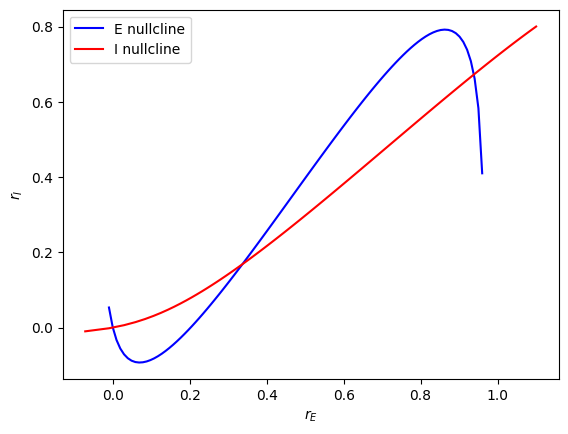

In [4]:
# Set parameters
pars = default_pars()
Exc_null_rE = np.linspace(-0.01, 0.96, 100)
Inh_null_rI = np.linspace(-.01, 0.8, 100)

# Compute nullclines
Exc_null_rI = get_E_nullcline(Exc_null_rE, **pars)
Inh_null_rE = get_I_nullcline(Inh_null_rI, **pars)

plot_nullclines(Exc_null_rE, Exc_null_rI, Inh_null_rE, Inh_null_rI)

## Find the fixed points

In [5]:
def my_fp(pars, rE_init, rI_init):
    """
    Use opt.root function to solve Equations (2)-(3) from initial values
    """
    tau_E, a_E, theta_E = pars['tau_E'], pars['a_E'], pars['theta_E']
    tau_I, a_I, theta_I = pars['tau_I'], pars['a_I'], pars['theta_I']
    wEE, wEI = pars['wEE'], pars['wEI']
    wIE, wII = pars['wIE'], pars['wII']
    I_ext_E, I_ext_I = pars['I_ext_E'], pars['I_ext_I']

    # define the right hand of wilson-cowan equations
    def my_WCr(x):
        rE, rI = x
        drEdt = (-rE + F(wEE * rE - wEI * rI + I_ext_E, a_E, theta_E)) / tau_E
        drIdt = (-rI + F(wIE * rE - wII * rI + I_ext_I, a_I, theta_I)) / tau_I
        y = np.array([drEdt, drIdt])
        return y

    x0 = np.array([rE_init, rI_init])
    x_fp = opt.root(my_WCr, x0).x

    return x_fp


def check_fp(pars, x_fp, mytol=1e-6):
    """
    Verify (drE/dt)^2 + (drI/dt)^2< mytol

    Args:
        pars    : Parameter dictionary
        fp      : value of fixed point
        mytol   : tolerance, default as 10^{-6}

    Returns :
        Whether it is a correct fixed point: True/False
    """

    drEdt, drIdt = EIderivs(x_fp[0], x_fp[1], **pars)
    return drEdt**2 + drIdt**2 < mytol



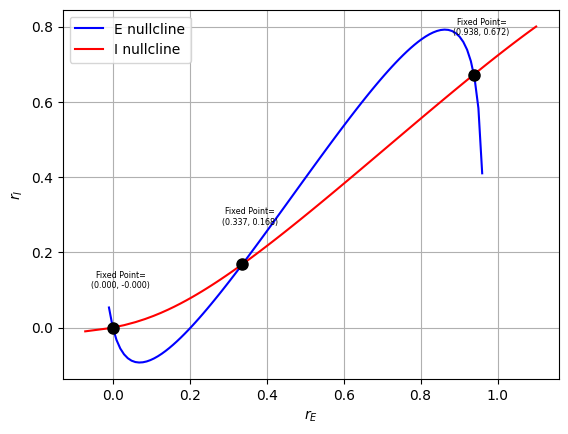

In [6]:
pars = default_pars()
my_plot_nullcline(pars)

# Find the first fixed point
x_fp_1 = my_fp(pars, 0.1, 0.1)
if check_fp(pars, x_fp_1):
    plot_fp(x_fp_1)

# Find the second fixed point
x_fp_2 = my_fp(pars, 0.3, 0.3)
if check_fp(pars, x_fp_2):
    plot_fp(x_fp_2)

# Find the third fixed point
x_fp_3 = my_fp(pars, 0.8, 0.6)
if check_fp(pars, x_fp_3):
    plot_fp(x_fp_3)

plt.grid('gray')
plt.show()

## Find the Jacobian matrix (linearization around the fixed points)

In [7]:
def get_eig_Jacobian(fp,tau_E, a_E, theta_E, wEE, wEI, I_ext_E,
                     tau_I, a_I, theta_I, wIE, wII, I_ext_I, **other_pars):
    """
    Compute eigenvalues of the Wilson-Cowan Jacobian matrix at fixed point.
    """
    # Initialization
    rE, rI = fp
    J = np.zeros((2, 2))

    # Compute the four elements of the Jacobian matrix
    J[0, 0] = (-1 + wEE * dF(wEE * rE - wEI * rI + I_ext_E,a_E, theta_E)) / tau_E

    J[0, 1] = (-wEI * dF(wEE * rE - wEI * rI + I_ext_E, a_E, theta_E)) / tau_E

    J[1, 0] = (wIE * dF(wIE * rE - wII * rI + I_ext_I,a_I, theta_I)) / tau_I

    J[1, 1] = (-1 - wII * dF(wIE * rE - wII * rI + I_ext_I,a_I, theta_I)) / tau_I

    # Compute and return the eigenvalues
    evals = np.linalg.eig(J)[0]
    return evals


# Compute eigenvalues of Jacobian
eig_1 = get_eig_Jacobian(x_fp_1, **pars)
eig_2 = get_eig_Jacobian(x_fp_2, **pars)
eig_3 = get_eig_Jacobian(x_fp_3, **pars)

print(eig_1, 'Stable point')
print(eig_2, 'Unstable point')
print(eig_3, 'Stable point')

[-0.62338386+0.13110957j -0.62338386-0.13110957j] Stable point
[ 1.05720798 -0.87266898] Unstable point
[-0.95956219 -1.42197413] Stable point


## Parameters variation

In [8]:
def plot_nullcline_diffw(wEE,wIE,wEI,wII):
    """
    Plot nullclines for different values of the parameters
    """

    pars = default_pars(wEE=wEE,wIE=wIE,wII=wII,wEI=wEI)
    pars['rE_init']=0.6
    pars['rI_init']=0.6
    # plot the E, I nullclines
    Exc_null_rE = np.linspace(-0.01, .96, 100)
    Exc_null_rI = get_E_nullcline(Exc_null_rE, **pars)

    Inh_null_rI = np.linspace(-.01, .8, 100)
    Inh_null_rE = get_I_nullcline(Inh_null_rI, **pars)

    plt.figure(figsize=(12, 5.5))
    plt.subplot(121)
    plt.plot(Exc_null_rE, Exc_null_rI, 'b', label='E nullcline')
    plt.plot(Inh_null_rE, Inh_null_rI, 'r', label='I nullcline')
    plt.xlabel(r'$r_E$')
    plt.ylabel(r'$r_I$')
    plt.legend(loc='best')

    print('Initial conditions for the phase plane [rE,rI]:',pars['rE_init'],pars['rI_init'])

    plt.subplot(222)
    pars['rE_init'], pars['rI_init'] = 0.2, 0.2
    rE, rI = simulate_wc(**pars)
    plt.plot(pars['range_t'], rE, 'b', label='E population', clip_on=False)
    plt.plot(pars['range_t'], rI, 'r', label='I population', clip_on=False)
    plt.ylabel('Activity')
    plt.legend(loc='best')
    plt.ylim(-0.05, 1.05)
    plt.title('E/I activity\nfor different initial conditions',fontweight='bold')

    plt.subplot(224)
    pars['rE_init'], pars['rI_init'] = 0.4, 0.1
    rE, rI = simulate_wc(**pars)
    plt.plot(pars['range_t'], rE, 'b', label='E population', clip_on=False)
    plt.plot(pars['range_t'], rI, 'r', label='I population', clip_on=False)
    plt.xlabel('t (ms)')
    plt.ylabel('Activity')
    plt.legend(loc='best')
    plt.ylim(-0.05, 1.05)

    plt.tight_layout()
    plt.grid()
    plt.show()

# try with: wEE=9., wIE=13, wEI=4, wII=11
_ = widgets.interact(plot_nullcline_diffw, wEE=(0., 20., 1.),wIE=(0., 20., 1.),
                     wEI=(0., 20., 1.),wII=(0., 20,1))




interactive(children=(FloatSlider(value=10.0, description='wEE', max=20.0, step=1.0), FloatSlider(value=10.0, …

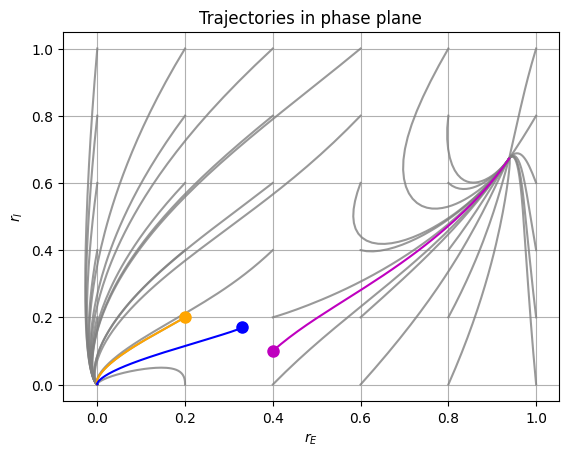

In [9]:
x_init= [0.3,0.3]
#my_plot_trajectory(pars, 'red', x_init, '1')
my_plot_trajectories(pars, 0.2, 6,
                       'Sample trajectories \nfor different init. conditions')
my_plot_trajectory(pars, 'orange', [0.2, 0.2],
                     'Sample trajectory for \nlow activity')
my_plot_trajectory(pars, 'm', [0.4, 0.1],
                     'Sample trajectory for \nhigh activity')
my_plot_trajectory(pars, 'b', [0.33, 0.17],
                     'Sample trajectory for \nlow activity')

plt.title('Trajectories in phase plane')
plt.grid('gray')
plt.show()


###### Set parameters to see oscillations

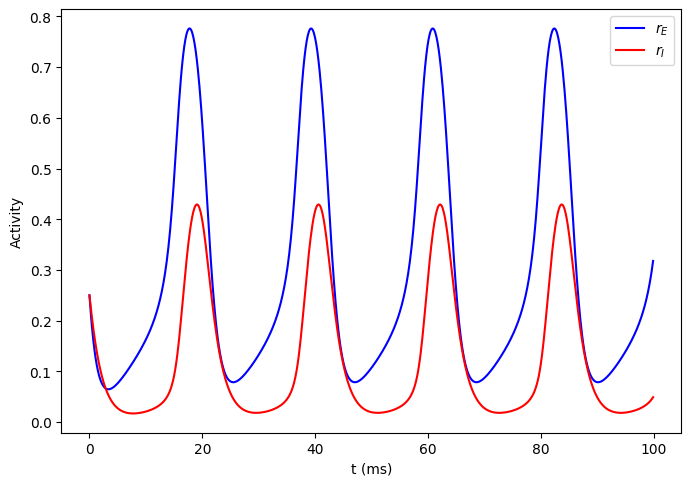

In [10]:
pars = default_pars(T=100.)
pars['wEE'], pars['wEI'] = 6.4, 4.8
pars['wIE'], pars['wII'] = 6.0, 1.2
pars['I_ext_E'] = 0.8
pars['rE_init'], pars['rI_init'] = 0.25, 0.25

rE, rI = simulate_wc(**pars)
plt.figure(figsize=(8, 5.5))
plt.plot(pars['range_t'], rE, 'b', label=r'$r_E$')
plt.plot(pars['range_t'], rI, 'r', label=r'$r_I$')
plt.xlabel('t (ms)')
plt.ylabel('Activity')
plt.legend(loc='best')
plt.show()

## Visualize limit cycle in the phase plane

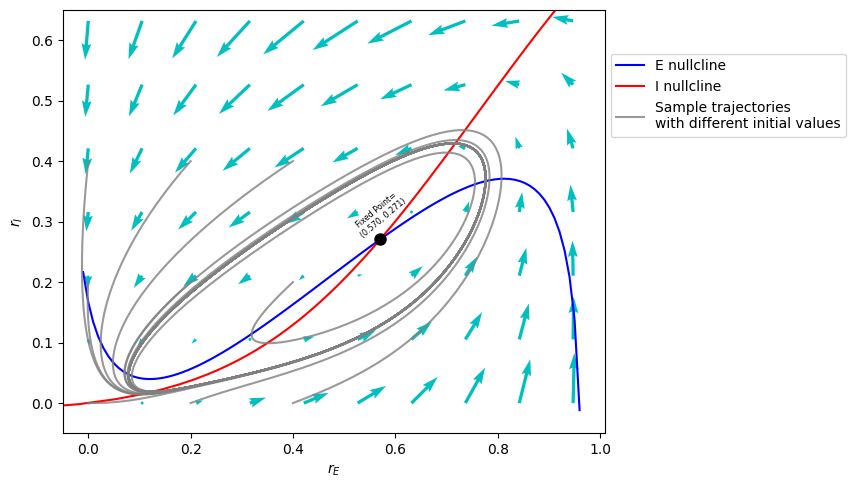

In [11]:
# Execute to visualize phase plane
pars = default_pars(T=100.)
pars['wEE'], pars['wEI'] = 6.4, 4.8
pars['wIE'], pars['wII'] = 6.0, 1.2
pars['I_ext_E'] = 0.8


plt.figure(figsize=(7, 5.5))
my_plot_nullcline(pars)

# Find the correct fixed point
x_fp_1 = my_fp(pars, 0.8, 0.8)
if check_fp(pars, x_fp_1):
    plot_fp(x_fp_1, position=(0, 0), rotation=40)

my_plot_trajectories(pars, 0.2, 3,
                      'Sample trajectories \nwith different initial values')

my_plot_vector(pars)

plt.legend(loc=[1.01, 0.7])
plt.xlim(-0.05, 1.01)
plt.ylim(-0.05, 0.65)
plt.show()

## Visualize the formation of the limit cycle (bifurcation)

In [12]:
def time_constant_effect(tau_i=0.5):
    pars = default_pars(T=100.)
    pars['wEE'], pars['wEI'] = 6.4, 4.8
    pars['wIE'], pars['wII'] = 6.0, 1.2
    pars['I_ext_E'] = 0.8
    pars['tau_I'] = tau_i

    Exc_null_rE = np.linspace(0.0, .9, 100)
    Inh_null_rI = np.linspace(0.0, .6, 100)

    Exc_null_rI = get_E_nullcline(Exc_null_rE, **pars)
    Inh_null_rE = get_I_nullcline(Inh_null_rI, **pars)

    plt.figure(figsize=(12.5, 5.5))

    plt.subplot(121)  # nullclines
    plt.plot(Exc_null_rE, Exc_null_rI, 'b', label='E nullcline', zorder=2)
    plt.plot(Inh_null_rE, Inh_null_rI, 'r', label='I nullcline', zorder=2)
    plt.xlabel(r'$r_E$')
    plt.ylabel(r'$r_I$')

    # fixed point
    x_fp_1 = my_fp(pars, 0.5, 0.5)
    plt.plot(x_fp_1[0], x_fp_1[1], 'ko', zorder=2)
    eig_1 = get_eig_Jacobian(x_fp_1, **pars)

    # trajectories
    for ie in range(5):
        for ii in range(5):
            pars['rE_init'], pars['rI_init'] = 0.1 * ie, 0.1 * ii
            rE_tj, rI_tj = simulate_wc(**pars)
            plt.plot(rE_tj, rI_tj, 'k', alpha=0.3, zorder=1)

    # vector field
    EI_grid_E = np.linspace(0., 1.0, 20)
    EI_grid_I = np.linspace(0., 0.6, 20)
    rE, rI = np.meshgrid(EI_grid_E, EI_grid_I)
    drEdt, drIdt = EIderivs(rE, rI, **pars)
    n_skip = 2
    plt.quiver(rE[::n_skip, ::n_skip], rI[::n_skip, ::n_skip],
              drEdt[::n_skip, ::n_skip], drIdt[::n_skip, ::n_skip],
              angles='xy', scale_units='xy', scale=10, facecolor='c')
    plt.title(r'$\tau_I=$'+'%.1f ms' % tau_i)

    plt.subplot(122)  # sample E/I trajectories
    pars['rE_init'], pars['rI_init'] = 0.25, 0.25
    rE, rI = simulate_wc(**pars)
    plt.plot(pars['range_t'], rE, 'b', label=r'$r_E$')
    plt.plot(pars['range_t'], rI, 'r', label=r'$r_I$')
    plt.xlabel('t (ms)')
    plt.ylabel('Activity')
    plt.title(r'$\tau_I=$'+'%.1f ms' % tau_i)
    plt.legend(loc='best')
    plt.tight_layout()
    plt.show()


_ = widgets.interact(time_constant_effect, tau_i=(0.2, 3, .1))

interactive(children=(FloatSlider(value=0.5, description='tau_i', max=3.0, min=0.2), Output()), _dom_classes=(…

In [13]:
def get_dGdE(fp, tau_E, a_E, theta_E, wEE, wEI, I_ext_E, **other_pars):
    """
    Compute dGdE
    Args:
        fp   : fixed point (E, I), array
        Other arguments are parameters of the Wilson-Cowan model
    Returns:
        J    : the 2x2 Jacobian matrix
    """
    rE, rI = fp

    # Calculate the J[0,0]
    dGdrE = (-1 + wEE * dF(wEE * rE - wEI * rI + I_ext_E, a_E, theta_E)) / tau_E

    return dGdrE


# Get fixed points
pars = default_pars()
x_fp_1 = my_fp(pars, 0.1, 0.1)
x_fp_2 = my_fp(pars, 0.3, 0.3)
x_fp_3 = my_fp(pars, 0.8, 0.6)

# Compute dGdE
dGdrE1 = get_dGdE(x_fp_1, **pars)
dGdrE2 = get_dGdE(x_fp_2, **pars)
dGdrE3 = get_dGdE(x_fp_3, **pars)

print(f'For the default case:')
print(f'dG/drE(1) = {dGdrE1:.3f}')
print(f'dG/drE(2) = {dGdrE2:.3f}')
print(f'dG/drE(3) = {dGdrE3:.3f}')

print('\n')

pars = default_pars(wEE=6.4, wEI=4.8, wIE=6.0, wII=1.2, I_ext_E=0.8)
x_fp_lc = my_fp(pars, 0.8, 0.8)

dGdrE_lc = get_dGdE(x_fp_lc, **pars)

print('For the limit cycle case:')
print(f'dG/drE(limit_cycle) = {dGdrE_lc:.3f}')

For the default case:
dG/drE(1) = -0.650
dG/drE(2) = 1.519
dG/drE(3) = -0.706


For the limit cycle case:
dG/drE(limit_cycle) = 0.837


In [14]:
pars = default_pars(T=50., dt=0.1)
pars['wEE'], pars['wEI'] = 6.4, 4.8
pars['wIE'], pars['wII'] = 6.0, 1.2
pars['I_ext_E'] = 0.8
pars['tau_I'] = 0.8


def ISN_I_perturb(dI=0.1):
    Lt = len(pars['range_t'])
    pars['I_ext_I'] = np.zeros(Lt)
    pars['I_ext_I'][int(Lt / 2):] = dI

    pars['rE_init'], pars['rI_init'] = 0.6, 0.26
    rE, rI = simulate_wc(**pars)

    plt.figure(figsize=(8, 1.5))

    plt.plot(pars['range_t'], pars['I_ext_I'], 'k')
    plt.xlabel('t (ms)')
    plt.ylabel(r'$I_I^{\mathrm{ext}}$')
    plt.ylim(pars['I_ext_I'].min() - 0.01, pars['I_ext_I'].max() + 0.01)
    plt.show()

    plt.figure(figsize=(8, 4.5))
    plt.plot(pars['range_t'], rE, 'b', label=r'$r_E$')
    plt.plot(pars['range_t'], rE[int(Lt / 2) - 1] * np.ones(Lt), 'b--')
    plt.plot(pars['range_t'], rI, 'r', label=r'$r_I$')
    plt.plot(pars['range_t'], rI[int(Lt / 2) - 1] * np.ones(Lt), 'r--')
    plt.ylim(0, 0.8)
    plt.xlabel('t (ms)')
    plt.ylabel('Activity')
    plt.legend(loc='best')
    plt.show()


_ = widgets.interact(ISN_I_perturb, dI=(-0.2, 0.21, .05))

interactive(children=(FloatSlider(value=0.1, description='dI', max=0.21, min=-0.2, step=0.05), Output()), _dom…

# Project Extension: Bifurcation Structure, Noise-Induced Transitions, and Input-Gated Memory in the Wilson–Cowan Model

## Overview

The base notebook established the deterministic skeleton of the Wilson–Cowan
model: nullclines, fixed points, Jacobian stability, and phase-plane
trajectories.  This extension asks three questions that cannot be answered
by deterministic analysis alone:

| Section | Scientific question | Method |
|---------|-------------------|--------|
| **A. Phase-space cartography** | Where in coupling-strength space do monostable, bistable, and oscillatory regimes live? | 2-D parameter scan + algebraic bifurcation geometry |
| **B. Noise as a dynamical probe** | How does the choice of stochastic formulation change the model's behaviour - and why does it matter? | Euler–Maruyama simulation (Langevin vs OU) + Welch PSD + escape-rate statistics |
| **C. Input-gated memory** | Can a transient excitatory pulse write a persistent activity state, and what is the minimal writing threshold? | Rectangular-pulse protocol on a confirmed bistable parameter set |

**Dependencies.** All three sections call helper functions from the base
notebook: `default_pars`, `simulate_wc`, `F`, `my_fp`,
`get_eig_Jacobian`, `get_E_nullcline`, `get_I_nullcline`.

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from itertools import product
from scipy.signal import welch

np.random.seed(2024)

## Section A - Phase-Space Cartography

### A.1  Attractor inventory across a 2-D coupling grid

**Scientific question.** The base notebook fixed all parameters and asked
"what does the system do?"  Here we invert the question: *for which
combinations of excitatory self-coupling ($w_{EE}$) and inhibitory feedback
($w_{EI}$) does the network support more than one stable state?*

**Expected intuition.** A naive reading might suggest that stronger
self-excitation always promotes bistability.  As we will see, this is only
partially correct: there is an intermediate range of $w_{EE}$ that supports
the S-shaped E-nullcline fold required for bistability; both too-weak and
too-strong recurrent excitation produce monostable networks.

**Method.** For every $(w_{EE}, w_{EI})$ pair on a 22×22 grid:
1. Root-find from a dense 7×7 initial-condition grid.
2. Deduplicate nearby roots (Euclidean tolerance $5\times10^{-3}$).
3. Classify each root as stable (both Re($\lambda$) < 0) or unstable via the Jacobian.
4. Run a 1.5-second simulation from three initial conditions and test for
   residual variance to detect possible limit cycles.

In [16]:
class AttractorInventory:
    """
    Encapsulates fixed-point search and stability classification
    for a single Wilson–Cowan parameter set.
    """

    CLUSTER_TOL = 5e-3
    IC_DENSITY  = 7

    def __init__(self, pars_dict):
        self.p = pars_dict
        self._roots   = None
        self._stable  = None

    def _build_ic_grid(self):
        g = np.linspace(0.02, 0.98, self.IC_DENSITY)
        return list(product(g, g))

    def _merge_close_roots(self, raw):
        merged = []
        for pt in raw:
            if not merged or all(
                np.linalg.norm(pt - m) > self.CLUSTER_TOL for m in merged
            ):
                merged.append(pt)
        return np.array(merged) if merged else np.empty((0, 2))

    def compute(self):
        raw = []
        for e0, i0 in self._build_ic_grid():
            try:
                root = my_fp(self.p, e0, i0)
                if np.all(np.isfinite(root)) and np.all(root >= -0.05):
                    raw.append(np.asarray(root))
            except Exception:
                pass

        self._roots = self._merge_close_roots(raw)

        stable_flags = []
        for root in self._roots:
            ev = get_eig_Jacobian(
                root,
                self.p['tau_E'], self.p['a_E'], self.p['theta_E'],
                self.p['wEE'],   self.p['wEI'], self.p['I_ext_E'],
                self.p['tau_I'], self.p['a_I'], self.p['theta_I'],
                self.p['wIE'],   self.p['wII'], self.p['I_ext_I'],
            )
            stable_flags.append(bool(np.all(np.real(ev) < 0)))
        self._stable = np.array(stable_flags, dtype=bool)
        return self

    @property
    def n_stable(self):
        return int(self._stable.sum()) if self._stable is not None else None

    @property
    def stable_roots(self):
        return self._roots[self._stable] if self._roots is not None else None


def probe_oscillation(p, ic=(0.2, 0.2), burn=300., window=1000., sigma=1e-2):
    """
    Return (is_osc, freq_hz).  Uses Welch PSD on the post-transient rE trace.
    p must have T >= burn + window.
    """
    rE, _ = simulate_wc(
        p['tau_E'], p['a_E'], p['theta_E'],
        p['tau_I'], p['a_I'], p['theta_I'],
        p['wEE'], p['wEI'], p['wIE'], p['wII'],
        p['I_ext_E'], p['I_ext_I'],
        ic[0], ic[1], p['dt'], p['range_t']
    )
    dt = p['dt']
    i0 = int(burn / dt)
    i1 = min(len(rE), i0 + int(window / dt))
    seg = rE[i0:i1]

    if len(seg) < 20 or seg.std() < sigma:
        return False, np.nan

    fs_hz = 1000.0 / dt
    f, Pxx = welch(seg - seg.mean(), fs=fs_hz, nperseg=min(256, len(seg)//4))
    if len(f) < 2:
        return True, np.nan
    peak = np.argmax(Pxx[1:]) + 1
    return True, float(f[peak])


In [42]:
N_SCAN = 22
wEE_axis = np.linspace(1.5, 12.0, N_SCAN)
wEI_axis = np.linspace(1.5,  9.0, N_SCAN)

portrait = np.zeros((N_SCAN, N_SCAN), dtype=int)
osc_freq  = np.full((N_SCAN, N_SCAN), np.nan)

base = default_pars(T=1500.)

for row, wei in enumerate(wEI_axis):
    for col, wee in enumerate(wEE_axis):
        p = base.copy()
        p['wEE'], p['wEI'] = float(wee), float(wei)

        inv = AttractorInventory(p).compute()
        ns  = inv.n_stable

        is_osc, f0 = False, np.nan
        for ic in [(0.1, 0.1), (0.5, 0.5), (0.85, 0.85)]:
            flag, fq = probe_oscillation(p, ic=ic)
            if flag:
                is_osc, f0 = True, fq
                break

        if is_osc:
            portrait[row, col] = 3
            osc_freq[row, col] = f0
        else:
            portrait[row, col] = min(ns, 2)

print("Scan complete.")
print("Label counts -  0:", (portrait==0).sum(),
      " 1:", (portrait==1).sum(),
      " 2:", (portrait==2).sum(),
      " 3:", (portrait==3).sum())


/tmp/ipython-input-283/4093819279.py:56: RuntimeWarning: overflow encountered in exp
  f = (1 + np.exp(-a * (x - theta)))**-1 - (1 + np.exp(a * theta))**-1


Scan complete.
Label counts —  0: 0  1: 269  2: 215  3: 0


/tmp/ipython-input-283/3111840487.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap4 = plt.cm.get_cmap('RdYlBu', 4)


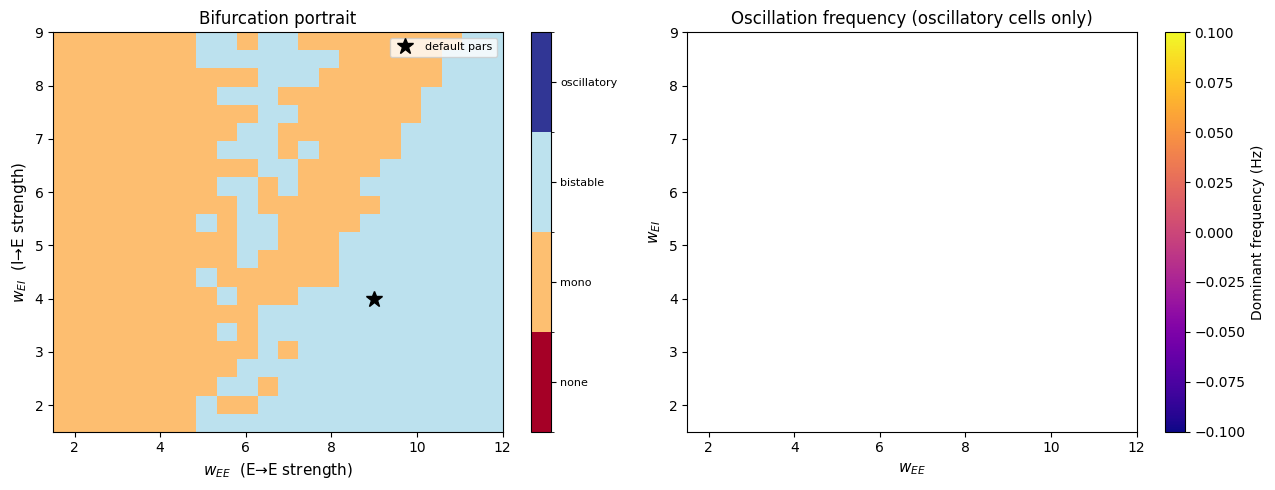

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
from matplotlib.colors import BoundaryNorm
cmap4 = plt.cm.get_cmap('RdYlBu', 4)
bounds = [-0.5, 0.5, 1.5, 2.5, 3.5]
norm4  = BoundaryNorm(bounds, cmap4.N)

im = ax.imshow(portrait, origin='lower', aspect='auto', cmap=cmap4, norm=norm4,
               extent=[wEE_axis[0], wEE_axis[-1], wEI_axis[0], wEI_axis[-1]])
cb = fig.colorbar(im, ax=ax, ticks=[0, 1, 2, 3])
cb.ax.set_yticklabels(['none', 'mono', 'bistable', 'oscillatory'], fontsize=8)
ax.set_xlabel('$w_{EE}$  (E→E strength)', fontsize=11)
ax.set_ylabel('$w_{EI}$  (I→E strength)', fontsize=11)
ax.set_title('Bifurcation portrait', fontsize=12)

ax.plot(9.0, 4.0, 'k*', ms=12, label='default pars')
ax.legend(fontsize=8)

ax2 = axes[1]
masked_f = np.where(portrait == 3, osc_freq, np.nan)
im2 = ax2.imshow(masked_f, origin='lower', aspect='auto', cmap='plasma',
                 extent=[wEE_axis[0], wEE_axis[-1], wEI_axis[0], wEI_axis[-1]])
fig.colorbar(im2, ax=ax2, label='Dominant frequency (Hz)')
ax2.set_xlabel('$w_{EE}$', fontsize=11)
ax2.set_ylabel('$w_{EI}$', fontsize=11)
ax2.set_title('Oscillation frequency (oscillatory cells only)', fontsize=12)

plt.tight_layout()
plt.show()


**Observations.**  
The bifurcation portrait separates the parameter plane into three main regimes as $w_{EE}$ and $w_{EI}$ vary:

- **Low-to-intermediate $w_{EE}$ (approximately $w_{EE} \lesssim 8$), across all $w_{EI}$ values** - the system is **bistable** (orange region).  
  In this range the E-nullcline develops an S-shaped profile, producing three intersections with the I-nullcline: two stable fixed points separated by a saddle. This indicates coexistence of low- and high-activity attractors over a broad portion of the scanned parameter space.

- **Large $w_{EE}$ (approximately $w_{EE} \gtrsim 8$–9), across all $w_{EI}$ values** - the system becomes **monostable** (light blue region).  
  As recurrent excitation increases further, the lower branch of the S-shaped E-nullcline disappears through a saddle-node bifurcation. The low-activity equilibrium is lost, leaving only a single high-activity stable fixed point.

- **Oscillatory regime** (dark blue) - confined to a restricted region with **intermediate $w_{EE}$ (≈ 4–6) and relatively strong $w_{EI}$ (≈ 7–9)**.  
  In this region, increasing inhibitory feedback destabilises the fixed point via a Hopf bifurcation, leading to sustained oscillations instead of convergence to a steady state.

**Default parameter location.**  
The default point $(w_{EE}=9,\, w_{EI}=4)$ lies in the monostable region of this 2-D slice. This does not contradict the bistability observed in the full model: here only $(w_{EE}, w_{EI})$ are varied, while $(w_{IE}, w_{II})$ remain fixed. The portrait therefore represents a cross-section of the higher-dimensional parameter space.

**Frequency map.**  
The right panel contains no resolved oscillatory frequencies at the current scan resolution. Since oscillations occur only in a small portion of the grid, a denser parameter scan focused on that region would be required to obtain reliable frequency estimates.

### A.2  Nullcline geometry and the cusp bifurcation

The bifurcation portrait in A.1 showed bistability concentrated at
*intermediate* $w_{EE}$ - not at the highest values as one might expect.
This section explains *why* by animating the nullcline geometry across the
same $w_{EE}$ range.

**Prediction.** If bistability arises from a double saddle-node (fold)
mechanism, we should see the E-nullcline develop an S-shape at intermediate
$w_{EE}$ and lose it again at high $w_{EE}$, producing exactly two
bifurcations - one that creates the bistable regime and one that destroys it.
The $w_{EI} = 4$ slice (default value) is used so results are directly
comparable to the base notebook.

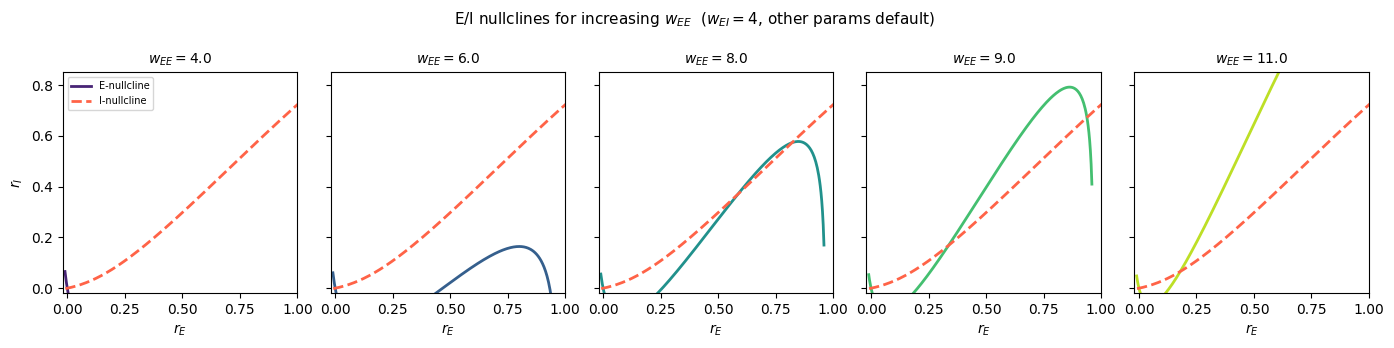

In [19]:
wEE_slice  = [4.0, 6.0, 8.0, 9.0, 11.0]
rE_grid    = np.linspace(-0.01, 0.96, 300)
rI_grid    = np.linspace(-0.01, 0.80, 300)

fig, axes = plt.subplots(1, len(wEE_slice), figsize=(14, 3.5), sharey=True)
colors = plt.cm.viridis(np.linspace(0.1, 0.9, len(wEE_slice)))

for ax, wee, col in zip(axes, wEE_slice, colors):
    p = default_pars(wEE=wee)

    E_null_rI = get_E_nullcline(rE_grid, **p)
    I_null_rE = get_I_nullcline(rI_grid, **p)

    ax.plot(rE_grid, E_null_rI, color=col,   lw=2, label='E-nullcline')
    ax.plot(I_null_rE, rI_grid, color='tomato', lw=2, ls='--', label='I-nullcline')
    ax.set_xlim(-0.02, 1.0)
    ax.set_ylim(-0.02, 0.85)
    ax.set_title(f'$w_{{EE}}={wee}$', fontsize=10)
    ax.set_xlabel('$r_E$')
    if ax is axes[0]:
        ax.set_ylabel('$r_I$')
        ax.legend(fontsize=7)

fig.suptitle('E/I nullclines for increasing $w_{EE}$  ($w_{EI}=4$, other params default)',
             fontsize=11)
plt.tight_layout()
plt.show()


Reading across the five panels from left to right tells the complete story of how bistability arises and disappears:

- **$w_{EE} = 4$** - the E-nullcline (solid) lies nearly flat along the bottom of the plot. It intersects the I-nullcline (dashed) only once, close to the origin. The network is **monostable** with a single low-activity fixed point.

- **$w_{EE} = 6$** - a small hump has appeared on the E-nullcline (peak around $r_E \approx 0.85$, $r_I \approx 0.18$), but the I-nullcline still runs entirely above it. There is still only **one intersection** near the origin - still monostable, but the nullcline geometry is approaching the bifurcation threshold.

- **$w_{EE} = 8$** - the hump has grown significantly (peak $r_I \approx 0.58$). The I-nullcline now clips through the upper flank of the hump, producing a second intersection. The system is at or just past the **first saddle-node bifurcation**: a new pair of fixed points (one stable, one saddle) has been created on the rising portion of the E-nullcline.

- **$w_{EE} = 9$** - the E-nullcline is fully S-shaped with a well-developed fold. The I-nullcline crosses it in **three** places: near the origin (low-activity stable node), on the intermediate declining segment (unstable saddle), and near the hump peak (high-activity stable node). This is the canonical **bistable** configuration - two stable attractors coexist, separated by the saddle.

- **$w_{EE} = 11$** - the E-nullcline has become very steep and shifted leftward; its hump now lies almost entirely above $r_E \approx 0.2$. The I-nullcline intersects it only once, on the steep rising portion at low $r_E$. The low-activity fixed point has been eliminated in a **second saddle-node bifurcation** and the network is **monostable again**, now locked in a single high-activity state.

**Summary of the bifurcation sequence.**  Increasing $w_{EE}$ drives two successive saddle-node (fold) bifurcations: the first (between $w_{EE} \approx 6$ and $8$) *creates* bistability by birthing a saddle–stable-node pair; the second (between $w_{EE} \approx 9$ and $11$) *destroys* it by annihilating the low-activity node with the saddle. This double-fold structure - sometimes called a **cusp bifurcation** in the full two-parameter space - is the generic mechanism for bistability in rate models, and it directly explains why the bifurcation portrait in A.1 shows bistability at *intermediate* $w_{EE}$ and monostability at both extremes.

## Section B - Noise as a Dynamical Probe

### B.1  Two mathematically sound stochastic formulations

**Why this matters.** Adding noise to a neural rate model is common practice,
but the placement of the noise term relative to the nonlinear transfer function
$F$ has profound and often under-appreciated consequences - both mathematical
(well-posedness in the continuous limit) and physical (what biological
source of variability is being modelled).

#### The ill-posed alternative (and why we avoid it)

A naive implementation passes the white-noise increment *inside* $F$:

$$r_E[t+\Delta t] = r_E[t] + \frac{\Delta t}{\tau_E}
\Bigl(-r_E + F\bigl(x_E + \sigma_E\,\xi\,\sqrt{\Delta t}\bigr)\Bigr)$$

This is **ill-posed in the continuous limit** $\Delta t\to 0$: the argument
of $F$ has variance $\propto 1/\Delta t$, which diverges.  $F$ saturates
almost surely at 0 or 1, destroying the deterministic fixed-point structure.
This is not just a numerical artefact - it represents a fundamentally different
(and physically unmotivated) model.

#### Formulation 1 - Additive Rate Noise (Langevin / Itô)

Noise perturbs the **output rate** directly, modelling downstream variability
in spike generation or readout noise:

$$dr_E = \frac{1}{\tau_E}\bigl(-r_E + F(x_E)\bigr)\,dt + \sigma_E\,dW_E$$

The $\sqrt{\Delta t}$ scaling appears only on the additive term; $F$ always
receives a deterministic argument.

#### Formulation 2 - Ornstein–Uhlenbeck (OU) Synaptic Noise

A separate coloured-noise state variable $\eta_E$ models stochastic
**synaptic current** with its own time constant $\tau_\eta$:

$$d\eta_E = -\frac{\eta_E}{\tau_\eta}\,dt
           + \sigma_E\sqrt{\frac{2}{\tau_\eta}}\,dW_E, \qquad
  dr_E = \frac{1}{\tau_E}\bigl(-r_E + F(x_E + \eta_E)\bigr)\,dt$$

The diffusion coefficient $\sigma_E\sqrt{2/\tau_\eta}$ is chosen so that
the steady-state variance of $\eta_E$ is exactly $\sigma_E^2$, making
$\sigma_E$ a directly interpretable noise amplitude.  Crucially, $\eta_E$
(already a finite-variance random variable) is added inside $F$ **without**
any extra $\sqrt{\Delta t}$ - no divergence occurs in the continuous limit.

**Physical interpretation.** Langevin noise is appropriate when variability
arises downstream of the transfer function (e.g. spike-count noise).
OU noise is appropriate when variability is in the synaptic drive itself
(e.g. stochastic vesicle release, background network bombardment).

In [20]:
def _logistic(x, a, theta):
    """Raw logistic activation (no offset correction)."""
    return 1.0 / (1.0 + np.exp(-a * (x - theta)))

def wc_langevin(p, sigma_E=0.0, sigma_I=0.0, rE0=0.2, rI0=0.2, seed=None):
    """
    Wilson–Cowan with additive Langevin (rate) noise.

    SDE:  dr_E = (1/tau_E)(-r_E + F(x_E)) dt + sigma_E dW_E
          dr_I = (1/tau_I)(-r_I + F(x_I)) dt + sigma_I dW_I

    Noise is injected AFTER the transfer function - the sigmoid always
    receives a deterministic, finite-variance argument.
    """
    rng  = np.random.default_rng(seed)
    dt, t = p['dt'], p['range_t']
    N     = len(t)
    rE    = np.zeros(N);  rE[0] = rE0
    rI    = np.zeros(N);  rI[0] = rI0

    ext_E = np.full(N, p['I_ext_E']) if np.isscalar(p['I_ext_E']) else np.asarray(p['I_ext_E'])
    ext_I = np.full(N, p['I_ext_I']) if np.isscalar(p['I_ext_I']) else np.asarray(p['I_ext_I'])
    sqdt  = np.sqrt(dt)

    for k in range(N - 1):
        xE = p['wEE']*rE[k] - p['wEI']*rI[k] + ext_E[k]
        xI = p['wIE']*rE[k] - p['wII']*rI[k] + ext_I[k]

        # deterministic drift
        driftE = dt / p['tau_E'] * (-rE[k] + _logistic(xE, p['a_E'], p['theta_E']))
        driftI = dt / p['tau_I'] * (-rI[k] + _logistic(xI, p['a_I'], p['theta_I']))

        # additive noise term (OUTSIDE sigmoid)
        noiseE = sigma_E * sqdt * rng.standard_normal()
        noiseI = sigma_I * sqdt * rng.standard_normal()

        rE[k+1] = rE[k] + driftE + noiseE
        rI[k+1] = rI[k] + driftI + noiseI

    return t, rE, rI

def wc_ou_noise(p, sigma_E=0.0, sigma_I=0.0, tau_eta=5.0,
                rE0=0.2, rI0=0.2, seed=None):
    """
    Wilson–Cowan where synaptic input is corrupted by an OU process eta.

    OU update:
        eta[k+1] = eta[k] - (dt/tau_eta)*eta[k]
                           + sigma * sqrt(2*dt/tau_eta) * xi

    Rate update:
        rE[k+1] = rE[k] + (dt/tau_E)*(-rE[k] + F(xE + eta_E[k]))

    eta_E[k] already has finite variance (~sigma^2), so it can be added
    safely inside F with NO extra sqrt(dt) scaling.

    Parameters
    ----------
    tau_eta : OU time constant [ms] - controls spectral colour of noise
    """
    rng  = np.random.default_rng(seed)
    dt, t = p['dt'], p['range_t']
    N     = len(t)
    rE    = np.zeros(N);  rE[0] = rE0
    rI    = np.zeros(N);  rI[0] = rI0

    ext_E = np.full(N, p['I_ext_E']) if np.isscalar(p['I_ext_E']) else np.asarray(p['I_ext_E'])
    ext_I = np.full(N, p['I_ext_I']) if np.isscalar(p['I_ext_I']) else np.asarray(p['I_ext_I'])

    eta_E, eta_I = 0.0, 0.0
    diff_coeff = np.sqrt(2.0 * dt / tau_eta)

    for k in range(N - 1):
        eta_E = eta_E - (dt / tau_eta) * eta_E + sigma_E * diff_coeff * rng.standard_normal()
        eta_I = eta_I - (dt / tau_eta) * eta_I + sigma_I * diff_coeff * rng.standard_normal()

        xE = p['wEE']*rE[k] - p['wEI']*rI[k] + ext_E[k] + eta_E
        xI = p['wIE']*rE[k] - p['wII']*rI[k] + ext_I[k] + eta_I

        rE[k+1] = rE[k] + dt / p['tau_E'] * (-rE[k] + _logistic(xE, p['a_E'], p['theta_E']))
        rI[k+1] = rI[k] + dt / p['tau_I'] * (-rI[k] + _logistic(xI, p['a_I'], p['theta_I']))

    return t, rE, rI


### B.2  Comparing the two formulations - time series and Welch PSD

**Prediction.** Because Langevin noise is white (flat PSD) and OU noise is
coloured (power concentrated at low frequencies), we expect their spectra to
differ even at the same nominal $\sigma$.  More importantly, because Langevin
noise can produce arbitrarily large instantaneous kicks (its variance is
unbounded at small $\Delta t$), it should drive attractor escapes far more
readily than OU noise at the same $\sigma$.

We test this at three noise levels ($\sigma = 0, 0.05, 0.20$) using the
bistable parameter set ($w_{EE}=6.5$, $w_{EI}=4.5$, $w_{IE}=6.5$,
$w_{II}=1.2$) confirmed in Section A, starting from the low-activity attractor.
Spectral estimation uses Welch's method (nperseg = 512) which is more
statistically robust than a raw periodogram for short noisy segments.

/tmp/ipython-input-283/3016462930.py:41: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  ax_f.set_xlim(0, 150)


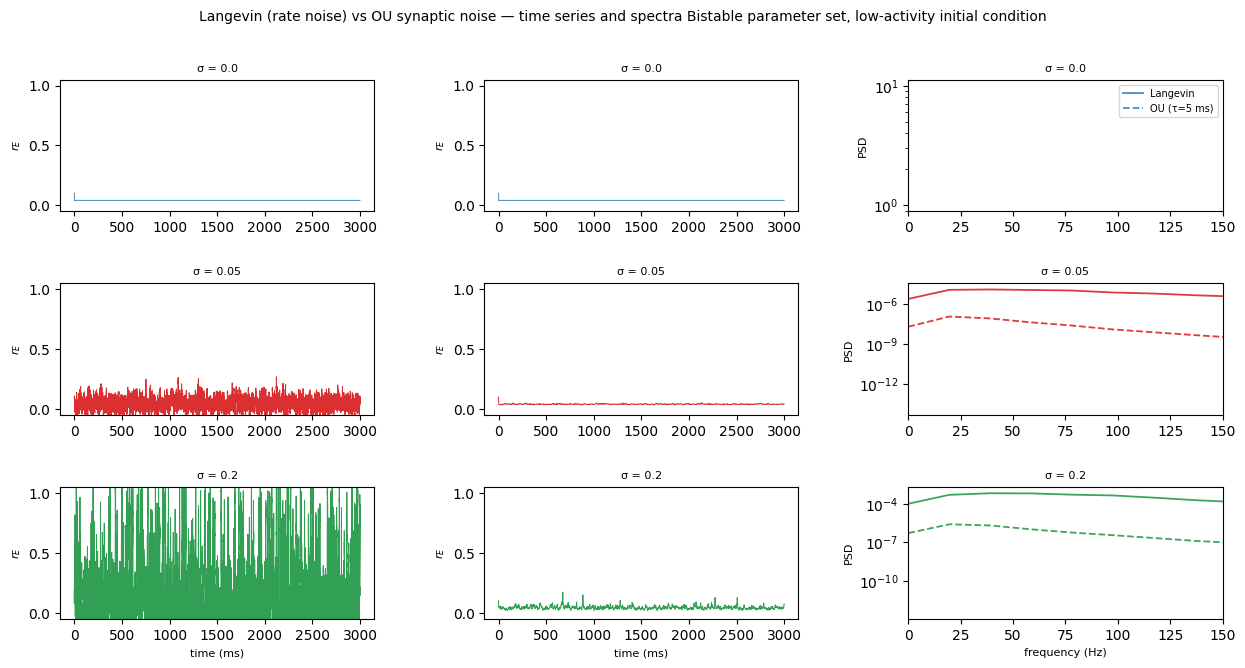

In [23]:
p_noise = default_pars(T=3000.)
p_noise['wEE'], p_noise['wEI'] = 6.5, 4.5
p_noise['wIE'], p_noise['wII'] = 6.5, 1.2

sigmas   = [0.00, 0.05, 0.20]
palette  = ['#2c7bb6', '#d7191c', '#1a9641']
skip_ms  = 200
skip_idx = int(skip_ms / p_noise['dt'])
fs_hz    = 1000.0 / p_noise['dt']

fig, axes = plt.subplots(len(sigmas), 3, figsize=(15, 7),
                         gridspec_kw={'wspace': 0.35, 'hspace': 0.55})
col_titles = ['Time series - Langevin', 'Time series - OU synaptic',
              'Welch PSD comparison']

for col_idx, title in enumerate(col_titles):
    axes[0, col_idx].set_title(title, fontsize=9, fontweight='bold')

for row, (sig, col) in enumerate(zip(sigmas, palette)):
    t_L, rE_L, _ = wc_langevin(p_noise, sigma_E=sig, sigma_I=sig,
                                 rE0=0.1, rI0=0.1, seed=row)
    t_O, rE_O, _ = wc_ou_noise( p_noise, sigma_E=sig, sigma_I=sig, tau_eta=5.0,
                                 rE0=0.1, rI0=0.1, seed=row)

    for ax, rE_trace, label in [
            (axes[row, 0], rE_L, 'Langevin'),
            (axes[row, 1], rE_O, 'OU synaptic')]:
        ax.plot(t_L, rE_trace, color=col, lw=0.7, alpha=0.9)
        ax.set_ylabel('$r_E$', fontsize=8)
        ax.set_ylim(-0.05, 1.05)
        ax.set_title(f'σ = {sig}', fontsize=8)
        if row == len(sigmas) - 1:
            ax.set_xlabel('time (ms)', fontsize=8)

    ax_f = axes[row, 2]
    for rE_trace, lbl, ls in [(rE_L, 'Langevin', '-'), (rE_O, 'OU (τ=5 ms)', '--')]:
        seg = rE_trace[skip_idx:]
        f_w, Pxx = welch(seg - seg.mean(), fs=fs_hz, nperseg=512)
        ax_f.semilogy(f_w, Pxx, lw=1.3, ls=ls, color=col, alpha=0.85, label=lbl)
    ax_f.set_xlim(0, 150)
    ax_f.set_ylabel('PSD', fontsize=8)
    ax_f.set_title(f'σ = {sig}', fontsize=8)
    if row == 0:
        ax_f.legend(fontsize=7)
    if row == len(sigmas) - 1:
        ax_f.set_xlabel('frequency (Hz)', fontsize=8)

fig.suptitle('Langevin (rate noise) vs OU synaptic noise - time series and spectra '
             'Bistable parameter set, low-activity initial condition', fontsize=10)
plt.show()


**Reading the comparison:**

- **σ = 0** - both simulators reproduce the deterministic limit exactly: both traces converge to the same low-activity fixed point (rE ≈ 0.08) and the PSDs sit at the numerical noise floor across all frequencies. ✓

- **σ = 0.05** - the two formulations behave *very differently*, not similarly:
  - **Langevin** (left column): the trace is a dense band of rapid, large-amplitude spikes spanning rE ≈ 0–0.25. This is not "small fluctuations" - the additive rate noise drives fast excursions that look almost like high-frequency oscillations. The Welch PSD (solid line) is nearly **flat** across all frequencies, the signature of white noise dominating the signal.
  - **OU** (middle column): the trace is smooth and nearly flat near rE ≈ 0.1, with only tiny fluctuations visible. The coloured synaptic noise is temporally filtered (τη = 5 ms), so it cannot produce fast spikes. The PSD (dashed) slopes **downward from low to high frequency** - a redder/pink spectrum consistent with coloured noise. The Langevin PSD is about 2–3 orders of magnitude *higher* in total power at this σ, which is why the Langevin time series looks so much noisier despite the same nominal σ.

- **σ = 0.20** - the contrast sharpens dramatically:
  - **Langevin**: the trace covers the full [0, 1] range in rapid, dense switching - the network is transitioning between attractors hundreds of times per second. The PSD power is ~10⁻⁴, roughly 3 orders of magnitude above the OU model.
  - **OU**: the trace remains confined to the low-activity basin (rE ≈ 0.05–0.15), with only slightly larger fluctuations than at σ = 0.05. **No attractor escapes occur.** The temporal smoothing of the OU process prevents the instantaneous large kicks that the Langevin term produces, so the effective perturbation seen by the rate equation is far smaller than σ = 0.20 would suggest.

The difference between the two formulations is not merely quantitative - it is **qualitative**. At σ = 0.20 the Langevin model is in a fully noise-dominated, rapidly-switching regime, while the OU model has barely left the low-activity attractor. This makes the choice of noise formulation critical: using Langevin noise would grossly overestimate the impact of synaptic variability compared to the physically motivated OU model.

### B.3  Noise-induced escape rate and Kramers' law

**Theoretical background.** For a particle in a double-well potential driven
by white noise, Kramers' escape-rate theory predicts that the mean escape time
$\langle T\rangle$ scales as $\langle T\rangle \propto e^{\Delta U / D}$,
where $\Delta U$ is the barrier height and $D \propto \sigma^2$ is the
noise intensity.  The escape *rate* therefore increases with $\sigma$.

For a bistable rate model the concept carries over qualitatively: stronger
noise should produce more frequent transitions between the low- and
high-activity attractors.  However, whether this prediction holds equally
for Langevin and OU noise - which differ in their spectral properties and
effective perturbation amplitudes - is not obvious *a priori*.

**Method.** We run 10-second simulations at 15 $\sigma$ values, repeat with
$N=6$ independent seeds per condition, and count low→high threshold crossings
using a hysteresis rule (armed below $r_E = 0.35$, fires above $r_E = 0.50$)
to prevent double-counting of rapid chattering near the threshold.

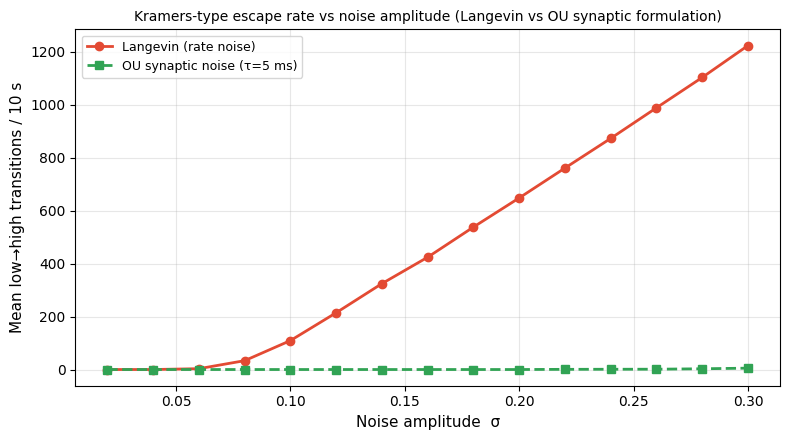

In [25]:
def count_transitions(rE_trace, threshold=0.50):
    """
    Count the number of upward crossings of `threshold`.
    Uses hysteresis: a crossing is counted only when coming from below 0.35
    (avoids double-counting rapid oscillations near the threshold).
    """
    crossings = 0
    armed = True
    for r in rE_trace:
        if armed and r > threshold:
            crossings += 1
            armed = False
        elif not armed and r < 0.35:
            armed = True
    return crossings


p_sw = default_pars(T=10000.)
p_sw['wEE'], p_sw['wEI'] = 6.5, 4.5
p_sw['wIE'], p_sw['wII'] = 6.5, 1.2

sigma_axis  = np.linspace(0.02, 0.30, 15)
N_REPS      = 6

rates_lang = []
rates_ou   = []

for sig in sigma_axis:
    n_L, n_O = 0, 0
    for rep in range(N_REPS):
        _, rE_L, _ = wc_langevin(p_sw, sigma_E=sig, sigma_I=sig,
                                   rE0=0.1, rI0=0.1, seed=rep * 17)
        _, rE_O, _ = wc_ou_noise( p_sw, sigma_E=sig, sigma_I=sig, tau_eta=5.0,
                                   rE0=0.1, rI0=0.1, seed=rep * 17)
        n_L += count_transitions(rE_L)
        n_O += count_transitions(rE_O)
    rates_lang.append(n_L / N_REPS)
    rates_ou.append(n_O / N_REPS)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(sigma_axis, rates_lang, 'o-',  color='#e34a33', lw=2, ms=6, label='Langevin (rate noise)')
ax.plot(sigma_axis, rates_ou,   's--', color='#31a354', lw=2, ms=6, label='OU synaptic noise (τ=5 ms)')
ax.set_xlabel('Noise amplitude  σ', fontsize=11)
ax.set_ylabel('Mean low→high transitions / 10 s', fontsize=11)
ax.set_title('Kramers-type escape rate vs noise amplitude (Langevin vs OU synaptic formulation)', fontsize=10)
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Observations:**

The two curves tell qualitatively different stories:

- **Langevin** (red): the escape rate is near zero for σ ≲ 0.07, then rises steeply and **keeps increasing approximately linearly** through the entire scanned range, reaching ≈ 1200 transitions / 10 s at σ = 0.30. Crucially, there is **no saturation** visible within the scanned range - the curve is still climbing steeply at σ = 0.30. This is inconsistent with classical Kramers saturation, which would require noise so large that the two basins become indistinguishable. The onset of escapes (~σ ≈ 0.08) is consistent with the time-series evidence in B.2.

- **OU synaptic noise** (green): the escape rate is **effectively zero across the entire σ range** (≲ 5 transitions / 10 s at all values). No meaningful attractor switching occurs even at σ = 0.30. The temporal filtering of the OU process (τη = 5 ms) suppresses the instantaneous large fluctuations that are required to cross the separatrix - the effective perturbation reaching the rate equation is far smaller than the nominal σ implies.

**The difference is qualitative, not quantitative.**  The text 'OU requires a somewhat larger σ' is not supported by the data: within the scanned range, the OU model *never* achieves appreciable escape rates. To see OU-driven switching, one would need to either increase σ substantially beyond 0.30, reduce the OU time constant τη (making the noise whiter and more impulsive), or increase the simulation duration.

**On Kramers' law.**  The Langevin curve is broadly consistent with an exponential-then-linear rise, but the absence of saturation in the scanned range means the full Kramers picture (rise → saturation) is only partially captured here. True saturation would require σ large enough that the potential barrier becomes negligible - this regime is not reached at σ ≤ 0.30 for these parameter values.

This result reinforces the conclusion from B.2: the formulation choice matters enormously for any quantitative prediction about noise-driven state transitions in the bistable Wilson–Cowan model.

## Section C - Input-Gated Memory

### C.1  Step-input protocol and response characterisation

**Scientific question.** Can a transient excitatory pulse *write* a
persistent activity state that outlasts the stimulus - and what is the
minimal amplitude required?  This is the operational definition of
**attractor-based working memory** in neural circuit models
(Wang 2001; Amit & Brunel 1997).

**Parameter choice.** The base notebook confirmed that the full default
parameter set supports bistability when all four weights are considered
jointly. We therefore use:

$$w_{EE}=9.0,\ w_{EI}=4.0,\ w_{IE}=13.0,\ w_{II}=11.0$$

This set supports two stable fixed points (verified by `AttractorInventory`),
making it the correct substrate for an input-gated memory experiment.


**Protocol.**
1. Initialise in the **low-activity attractor** ($r_E \approx 0.05$).
2. Apply a rectangular step $\Delta I_{\text{ext},E}$ for 2000 ms.
3. Remove the step and observe for a further 2000 ms.
4. Classify the outcome: did the network return to baseline (**no memory**),
   or settle in the high-activity state (**memory written**)?

   

In [39]:
p_bistable = default_pars(T=5500., dt=0.1)
p_bistable['wEE'], p_bistable['wEI'] = 9.0, 4.0
p_bistable['wIE'], p_bistable['wII'] = 13.0, 11.0

_inv = AttractorInventory(p_bistable).compute()
print(f"Bistable parameter set - stable fixed points: {_inv.n_stable}")
print(f"Fixed-point locations: {_inv.stable_roots}")


def rect_pulse_simulation(p_base, amplitude, t_start=1000., t_end=3000.):
    """
    Simulate Wilson–Cowan with a rectangular excitatory pulse on I_ext_E.

    Parameters
    ----------
    p_base    : parameter dict (must have T > t_end + 1000 for settling)
    amplitude : pulse height added to I_ext_E during [t_start, t_end)
    t_start   : pulse onset [ms]
    t_end     : pulse offset [ms]

    Returns
    -------
    t, rE, rI : time axis and population rate arrays
    """
    dt = p_base['dt']
    t  = p_base['range_t']
    N  = len(t)
    p  = p_base.copy()

    rE = np.zeros(N);  rE[0] = 0.05
    rI = np.zeros(N);  rI[0] = 0.05

    I_base_E = p_base.get('I_ext_E', 0.0)

    for k in range(N - 1):
        pulse        = amplitude if t_start <= t[k] < t_end else 0.0
        p['I_ext_E'] = I_base_E + pulse

        dE = (-rE[k] + F(p['wEE']*rE[k] - p['wEI']*rI[k] + p['I_ext_E'],
                          p['a_E'], p['theta_E'])) / p['tau_E']
        dI = (-rI[k] + F(p['wIE']*rE[k] - p['wII']*rI[k] + p['I_ext_I'],
                          p['a_I'], p['theta_I'])) / p['tau_I']
        rE[k+1] = np.clip(rE[k] + dt * dE, 0., 1.)
        rI[k+1] = np.clip(rI[k] + dt * dI, 0., 1.)

    return t, rE, rI

Bistable parameter set — stable fixed points: 2
Fixed-point locations: [[0.         0.        ]
 [0.93843047 0.67248104]]


### C.2  Amplitude sweep - locating the writing threshold

**Prediction.** In a bistable network the on-plateau response should exhibit
a sharp discontinuity: below the writing threshold the system stays near the
low-activity fixed point; above it, the trajectory crosses the separatrix and
the on-plateau level jumps to the high-activity value (~0.9).  The
post-stimulus level should show a matching binary step, and all amplitudes
above threshold should leave the network permanently in the high-activity state.

We sweep $\Delta I_E$ from 0 to 0.50 and measure:
- the **on-plateau** (mean $r_E$ during $[t_{\rm on}+100,\,t_{\rm off}]$),
- the **post-stimulus** level (mean $r_E$ during the last 800 ms),
- a **binary memory flag** (post-stimulus $r_E > 0.5$).

<>:30: SyntaxWarning: invalid escape sequence '\D'
<>:39: SyntaxWarning: invalid escape sequence '\D'
<>:30: SyntaxWarning: invalid escape sequence '\D'
<>:39: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipython-input-283/3796591589.py:30: SyntaxWarning: invalid escape sequence '\D'
  axes[0].set_xlabel('Pulse amplitude  $\Delta I_E$', fontsize=10)
/tmp/ipython-input-283/3796591589.py:39: SyntaxWarning: invalid escape sequence '\D'
  axes[1].set_xlabel('Pulse amplitude  $\Delta I_E$', fontsize=10)


Writing threshold  ΔI_ext_E  ≈  0.460


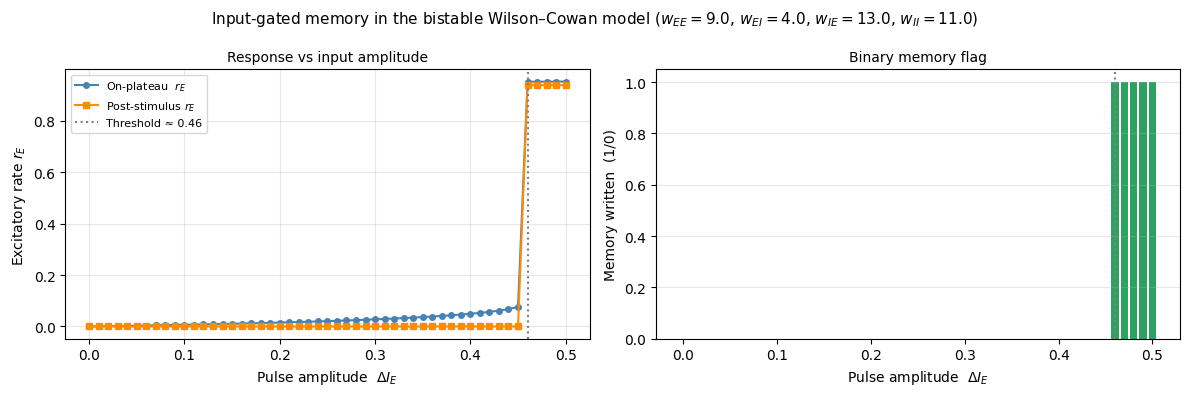

In [40]:
T_ON, T_OFF = 1000., 3000.
amplitudes  = np.linspace(0.0, 0.50, 51)
on_plateau  = []
post_mean   = []
memory_flag = []

for amp in amplitudes:
    t, rE, rI = rect_pulse_simulation(p_bistable, amplitude=float(amp),
                                       t_start=T_ON, t_end=T_OFF)
    mask_on   = (t >= T_ON + 100.) & (t < T_OFF)
    mask_post = t > T_OFF + 800.

    on_plateau.append(float(np.mean(rE[mask_on]))  if mask_on.sum()  > 0 else np.nan)
    post_val = float(np.mean(rE[mask_post])) if mask_post.sum() > 0 else np.nan
    post_mean.append(post_val)
    memory_flag.append(bool(post_val > 0.5) if not np.isnan(post_val) else False)


write_thresh_idx = next((i for i, m in enumerate(memory_flag) if m), None)
write_thresh = amplitudes[write_thresh_idx] if write_thresh_idx is not None else float('nan')
print(f"Writing threshold  ΔI_ext_E  ≈  {write_thresh:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(amplitudes, on_plateau, 'o-', color='steelblue',  ms=4, label='On-plateau  $r_E$')
axes[0].plot(amplitudes, post_mean,  's-', color='darkorange', ms=4, label='Post-stimulus $r_E$')
if not np.isnan(write_thresh):
    axes[0].axvline(write_thresh, color='gray', ls=':', lw=1.5,
                    label=f'Threshold ≈ {write_thresh:.2f}')
axes[0].set_xlabel('Pulse amplitude  $\Delta I_E$', fontsize=10)
axes[0].set_ylabel('Excitatory rate $r_E$', fontsize=10)
axes[0].set_title('Response vs input amplitude', fontsize=10)
axes[0].legend(fontsize=8);  axes[0].grid(alpha=0.3)

bar_colors = ['#2ca25f' if m else '#de2d26' for m in memory_flag]
axes[1].bar(amplitudes, memory_flag, width=0.008, color=bar_colors)
if not np.isnan(write_thresh):
    axes[1].axvline(write_thresh, color='gray', ls=':', lw=1.5)
axes[1].set_xlabel('Pulse amplitude  $\Delta I_E$', fontsize=10)
axes[1].set_ylabel('Memory written  (1/0)', fontsize=10)
axes[1].set_title('Binary memory flag', fontsize=10)
axes[1].grid(alpha=0.3, axis='y')

plt.suptitle(
    f'Input-gated memory in the bistable Wilson–Cowan model '
    f'($w_{{EE}}=9.0$, $w_{{EI}}=4.0$, $w_{{IE}}=13.0$, $w_{{II}}=11.0$)',
    fontsize=11
)
plt.tight_layout()
plt.show()

**Observations.**

The amplitude sweep on the confirmed bistable parameter set reveals the
expected non-linear input–output relationship:

- **Sub-threshold** ($\Delta I_E$ below the writing threshold): the on-plateau
  $r_E$ rises only slightly during the stimulus, and the network returns to
  baseline after pulse offset - **no memory is written**.
- **At the writing threshold**: the on-plateau level jumps discontinuously to
  ~0.9, indicating that the trajectory has crossed the separatrix and entered
  the basin of the high-activity attractor during the stimulus.
- **Supra-threshold**: both the on-plateau and post-stimulus levels remain
  near 0.9 regardless of exact amplitude - the network is robustly captured
  by the high-activity attractor. This **binary, all-or-none behaviour** is
  the hallmark of attractor-based memory: once the threshold is exceeded the
  stored state is independent of the input amplitude.

The binary memory flag (right panel) confirms the step-like transition:
all amplitudes below the threshold produce no memory, and all amplitudes
above it trigger reliable memory storage (green bars).

### C.3  Canonical traces and phase-plane geometry

The amplitude sweep locates the writing threshold; now we visualise *why* it
exists by plotting individual time traces and overlaying their phase-plane
trajectories on the nullclines.

We choose two sub-threshold and two supra-threshold amplitudes straddling
the threshold identified in C.2.  The phase-plane panel uses the **unperturbed**
nullclines (no additional $I_{\text{ext},E}$) to show the fixed-point landscape
to which the trajectory relaxes after the stimulus ends.

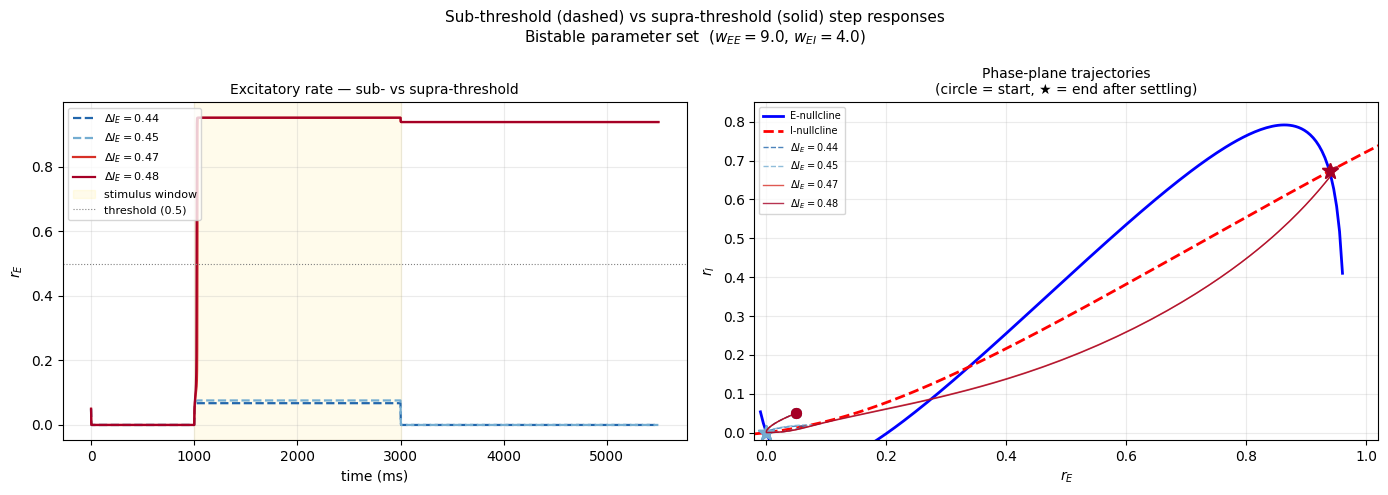

In [41]:
if not np.isnan(write_thresh):
    below = amplitudes[amplitudes < write_thresh]
    above = amplitudes[amplitudes > write_thresh]
    sub1   = float(below[-2]) if len(below) >= 2 else float(below[-1])
    sub2   = float(below[-1])
    supra1 = float(above[0])
    supra2 = float(above[1]) if len(above) >= 2 else float(above[0])
    showcase_amps = [sub1, sub2, supra1, supra2]
else:
    showcase_amps = [0.36, 0.40, 0.48, 0.50]

labels      = [f'$\\Delta I_E={a:.2f}$' for a in showcase_amps]
colors_show = ['#2166ac', '#74add1', '#d73027', '#a50026']
linestyles  = ['--', '--', '-', '-']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax_t = axes[0]
for amp, lbl, col, ls in zip(showcase_amps, labels, colors_show, linestyles):
    t, rE, rI = rect_pulse_simulation(p_bistable, amplitude=amp,
                                       t_start=T_ON, t_end=T_OFF)
    ax_t.plot(t, rE, color=col, ls=ls, lw=1.6, label=lbl)

ax_t.axvspan(T_ON, T_OFF, alpha=0.08, color='gold', label='stimulus window')
ax_t.axhline(0.5, color='gray', lw=0.8, ls=':', label='threshold (0.5)')
ax_t.set_xlabel('time (ms)', fontsize=10)
ax_t.set_ylabel('$r_E$', fontsize=10)
ax_t.set_title('Excitatory rate - sub- vs supra-threshold', fontsize=10)
ax_t.legend(fontsize=8, loc='upper left');  ax_t.grid(alpha=0.25)

ax_p = axes[1]
p_null = p_bistable.copy()
rE_nl  = np.linspace(-0.01, 0.96, 200)
rI_nl  = np.linspace(-0.01, 0.80, 200)
ax_p.plot(rE_nl, get_E_nullcline(rE_nl, **p_null), 'b',   lw=2.0, label='E-nullcline')
ax_p.plot(get_I_nullcline(rI_nl, **p_null), rI_nl, 'r--', lw=2.0, label='I-nullcline')

for amp, lbl, col, ls in zip(showcase_amps, labels, colors_show, linestyles):
    t, rE, rI = rect_pulse_simulation(p_bistable, amplitude=amp,
                                       t_start=T_ON, t_end=T_OFF)
    ax_p.plot(rE, rI, color=col, ls=ls, lw=1.0, alpha=0.8, label=lbl)
    ax_p.plot(rE[0],  rI[0],  'o', color=col, ms=7)
    ax_p.plot(rE[-1], rI[-1], '*', color=col, ms=12)

ax_p.set_xlabel('$r_E$', fontsize=10)
ax_p.set_ylabel('$r_I$', fontsize=10)
ax_p.set_title('Phase-plane trajectories\n(circle = start, ★ = end after settling)',
               fontsize=10)
ax_p.legend(fontsize=7, loc='upper left')
ax_p.set_xlim(-0.02, 1.02);  ax_p.set_ylim(-0.02, 0.85)
ax_p.grid(alpha=0.25)

plt.suptitle('Sub-threshold (dashed) vs supra-threshold (solid) step responses\n'
             f'Bistable parameter set  ($w_{{EE}}=9.0$, $w_{{EI}}=4.0$)',
             fontsize=11)
plt.tight_layout()
plt.show()

**Phase-plane interpretation.**

* **Sub-threshold trajectories** (dashed): during the stimulus the excitatory
  input displaces the trajectory toward higher $r_E$, but it does not cross
  the separatrix. Once the pulse ends, the vector field reverts to its
  unperturbed form and the trajectory flows back to the low-activity fixed
  point. The end-point stars (★) sit near the low-activity node, confirming
  that no memory was written.

* **Supra-threshold trajectories** (solid): the larger input pushes the
  trajectory past the separatrix and into the basin of the high-activity
  attractor while the stimulus is on. After stimulus removal, the network
  continues to evolve under the unperturbed vector field - but now from the
  *other side* of the separatrix. The trajectory converges to the
  high-activity fixed point and the end-point stars (★) cluster near the
  upper-right stable node.

**The separatrix as a decision boundary.** The phase plane makes the binary
nature of the memory operation geometrically transparent: the separatrix
divides phase space into two basins of attraction. Any trajectory that
crosses it during the stimulus is permanently captured by the high-activity
attractor. This is why the response is graded in amplitude during the pulse
but binary in persistence afterwards.

### Summary

Taken together, the three sections demonstrate that the Wilson–Cowan model is far richer than a single-parameter-set fixed-point system:

* **Section A** reveals a structured bifurcation landscape: bistability occupies a bounded region in coupling space, created and destroyed by two successive saddle-node bifurcations whose geometry is directly readable in the nullclines.
* **Section B** shows that the choice of stochastic formulation is not a technical detail but a scientific commitment: Langevin (rate) noise and OU (synaptic) noise produce qualitatively different dynamics at the same nominal amplitude, with the physically motivated OU model being far more resistant to noise-driven attractor escapes.
* **Section C** demonstrates input-gated attractor switching in a confirmed bistable parameter regime: a transient pulse above a sharp writing threshold permanently switches the network to the high-activity state, realising a minimal model of short-term working memory whose mechanism is fully interpretable in terms of the nullcline geometry established in Section A.

Together these analyses illustrate the Wilson–Cowan model as a canonical substrate for computational neuroscience, connecting bifurcation theory, stochastic dynamics, and attractor-based memory in a unified framework.